# UEFA Champions League 2026/27 - champion probability model

A reproducible pipeline that (1) collects historical Champions League results, (2) estimates team strength and match
outcome probabilities with leakage-safe features, (3) evaluates models **chronologically**, and (4) runs a Monte Carlo
simulation of the 36-team league phase and knockout bracket to estimate each club's chance of winning the trophy.

> **Read this first.** The output is a *probability table*, not a claim to know the winner. Every table and chart is
> stamped with the **forecast mode** that produced it:
> `LIVE_FORECAST` (official 2026/27 participants and fixtures were available), `HISTORICAL_REPLAY` (a past season replayed
> using only data from before its cutoff - **not** a forecast of the current season) or `SCENARIO` (assumed participants).
> If the official 2026/27 fixtures cannot be loaded, the notebook says so and falls back to a clearly labelled replay -
> it never invents data.

**Run it in Google Colab:** upload the project folder as a zip (or set `REPO_URL` below), optionally add a Colab secret named
`FOOTBALL_DATA_API_TOKEN` (free token: <https://www.football-data.org/client/register>), then *Runtime -> Run all*.
No GPU is needed.

## 1. Install dependencies and locate the project

In [1]:
import os, sys, glob, pathlib, subprocess

IN_COLAB = "google.colab" in sys.modules
REPO_URL = ""            # optional: "https://github.com/<you>/ucl-champion-predictor.git" to clone instead of uploading a zip

def find_root():
    here = pathlib.Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p / "src" / "pipeline.py").exists():
            return p
    return None

ROOT = find_root()
if ROOT is None and IN_COLAB:
    if REPO_URL:
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "/content/ucl-champion-predictor"], check=True)
    else:
        from google.colab import files
        import zipfile
        print("Upload the zipped project folder (ucl-champion-predictor.zip):")
        for name in files.upload():
            zipfile.ZipFile(name).extractall("/content")
    hits = glob.glob("/content/**/src/pipeline.py", recursive=True)
    ROOT = pathlib.Path(hits[0]).parents[1] if hits else None
if ROOT is None:
    raise RuntimeError("Could not find the project (src/pipeline.py). Open this notebook from inside the project folder, "
                       "or upload the project zip in Colab.")
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

if IN_COLAB:   # Colab already ships pandas / numpy / scikit-learn / matplotlib; this adds what is missing (e.g. catboost)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
print("project root:", ROOT, "| Colab:", IN_COLAB, "| python", sys.version.split()[0])

project root: C:\Users\admin\OneDrive\Desktop\IT Projects\ucl-champion-predictor | Colab: False | python 3.12.15


## 2. Configure API credentials securely

The football-data.org token is read from a **Colab secret**, an **environment variable**, or a git-ignored `.env` file -
never from the notebook source, and it is never printed. Without a token the project still runs on the public-domain
openfootball dataset (historical results only); only the *live* 2026/27 data needs the API.

In [2]:
from src.data_loader import TOKEN_ENV_VAR, get_api_token

ASK_IF_MISSING = False   # set True in Colab to be prompted for the token with a hidden input box

try:                                                   # 1) Colab secret (key icon in the left sidebar)
    from google.colab import userdata
    secret = userdata.get(TOKEN_ENV_VAR)
    if secret:
        os.environ[TOKEN_ENV_VAR] = secret
except Exception:
    pass

if not get_api_token() and ASK_IF_MISSING:             # 2) hidden prompt
    import getpass
    typed = getpass.getpass("football-data.org API token (input hidden, Enter to skip): ").strip()
    if typed:
        os.environ[TOKEN_ENV_VAR] = typed

TOKEN_OK = bool(get_api_token())                       # 3) environment variable / .env were checked by get_api_token()
print("football-data.org token configured:", TOKEN_OK)
if not TOKEN_OK:
    print("-> no token: historical data comes from the openfootball dataset and the live 2026/27 season cannot be loaded.")

football-data.org token configured: False
-> no token: historical data comes from the openfootball dataset and the live 2026/27 season cannot be loaded.


### Run configuration
Everything that changes a result lives in this one cell. `mode="auto"` tries the live 2026/27 forecast and otherwise falls
back to a labelled historical replay.

In [3]:
import warnings
import numpy as np
import pandas as pd
from IPython.display import display, Image

from src import pipeline as pl
from src.data_loader import as_of, describe_football_data_payload, clean_matches
from src.features import build_features, build_frozen_features
from src.simulator import (MODE_LIVE, MODE_REPLAY, MODE_SCENARIO, SimConfig, build_setup_from_matches,
                           build_scenario_setup, simulate_tournament)
from src.utils import season_label

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160, "display.max_columns", 30)

cfg = pl.RunConfig(
    mode="auto",                 # "auto" | "live" | "replay" | "scenario"
    target_season=2026,          # 2026 == 2026/27
    replay_season=2025,          # used for the historical replay (2024 or 2025: the 36-team format)
    replay_cutoff="2025-09-01",  # the replay may only use information from before this date
    n_sims=10_000, seed=42,
    include_catboost=True,       # optional gradient-boosting model; skipped automatically if not installed
    run_sensitivity=True,        # re-simulate under every candidate model to show model-choice uncertainty
    refresh=False,               # True = ignore cached raw snapshots and call the data sources again
)
cfg.paths.ensure()
print(cfg.mode, "| simulations:", cfg.n_sims, "| seed:", cfg.seed)

auto | simulations: 10000 | seed: 42


## 3. Download and validate the data

Sources are tried in priority order **per season**: football-data.org (REST API, needs a token) and, for every season it cannot
supply, openfootball (CC0 text files). Raw responses are snapshotted under `data/raw/` with the retrieval time, so re-running
does not hit the network again. Duplicates, impossible rows and missing scores are removed *and reported*; unavailable seasons
are listed with the reason - nothing is substituted silently.

In [4]:
full, provenance = pl.load_data(cfg)

print("seasons loaded per source:", pd.Series(provenance["season_source"]).value_counts().to_dict())
print("seasons NOT loaded:", provenance["seasons_not_loaded"] or "none")
for key, reason in provenance["unavailable"].items():
    print(f"  unavailable  {key}: {reason[:140]}")
print("\nvalidation report:", {k: v for k, v in provenance["validation"].items() if k != "warnings"})
for w in provenance["validation"]["warnings"]:
    print("  warning:", w)
print("retrieved at:", provenance["retrieved_at"])
print(f"\n{len(full):,} matches, {full['season'].nunique()} seasons "
      f"({season_label(int(full['season'].min()))} - {season_label(int(full['season'].max()))}), "
      f"{int(full['is_completed'].sum()):,} completed, {int((~full['is_completed']).sum())} not yet played")

23:11:55 WARNING ucl.pipeline: no football-data.org token configured -> using the openfootball public dataset only. The target-season (live) data therefore cannot be loaded.


23:11:55 WARNING ucl.data: season 2026 unavailable from openfootball: openfootball has no file for season 2026/27 (https://raw.githubusercontent.com/openfootball/champions-league/master/2026-27/cl.txt)


seasons loaded per source: {'openfootball': 15}
seasons NOT loaded: [2026]
  unavailable  openfootball:2026: NotFoundError: openfootball has no file for season 2026/27 (https://raw.githubusercontent.com/openfootball/champions-league/master/2026-27/c

validation report: {'n_rows': 1997, 'n_completed': 1997, 'n_fixtures': 0, 'duplicates_dropped': 0, 'dropped_invalid': 0}
retrieved at: {'openfootball': '2026-10-22T17:19:47+00:00'}

1,997 matches, 15 seasons (2011/12 - 2025/26), 1,997 completed, 0 not yet played


In [5]:
# Verify the real response schema of football-data.org instead of assuming it (only possible when that source was used).
import json
snap_dir = cfg.paths.data_raw / "football_data"
snaps = sorted(snap_dir.glob("CL_*.json")) if snap_dir.exists() else []
if snaps:
    probe = describe_football_data_payload(json.loads(snaps[-1].read_text(encoding="utf-8")))
    print("latest football-data.org snapshot:", snaps[-1].name)
    for k in ("n_matches", "stages", "statuses", "durations", "score_nodes", "unmapped_stages", "missing_required"):
        print(f"  {k}: {probe[k]}")
else:
    print("football-data.org was not used in this run (no token or no cached snapshot), so its response schema could not be\n"
          "verified here. The parser accepts both 'home/away' and 'homeTeam/awayTeam' score keys, derives the 90-minute score\n"
          "from regularTime (or fullTime - extraTime - penalties) and reports unmapped stage names; with a token this cell\n"
          "prints what the API actually returns.")

football-data.org was not used in this run (no token or no cached snapshot), so its response schema could not be
verified here. The parser accepts both 'home/away' and 'homeTeam/awayTeam' score keys, derives the 90-minute score
from regularTime (or fullTime - extraTime - penalties) and reports unmapped stage names; with a token this cell
prints what the API actually returns.


## 4. Explore the dataset

In [6]:
by_season = full.groupby("season").agg(matches=("match_id", "size"), completed=("is_completed", "sum"),
                                       teams=("home_team_id", "nunique"))
done = full[full["is_completed"]]
by_season["goals_per_match"] = (done["home_goals_90"] + done["away_goals_90"]).groupby(done["season"]).mean()
by_season["home_win_%"] = 100 * (done["home_goals_90"] > done["away_goals_90"]).groupby(done["season"]).mean()
by_season["draw_%"] = 100 * (done["home_goals_90"] == done["away_goals_90"]).groupby(done["season"]).mean()
by_season.index = [season_label(int(s)) for s in by_season.index]
display(by_season.round(2))
print("matches by stage:", full["stage"].value_counts().to_dict())
print("distinct clubs:", pd.concat([full["home_team_id"], full["away_team_id"]]).nunique())

,matches,completed,teams,goals_per_match,home_win_%,draw_%
2011/12,125,125,32,2.75,49.60,25.60
2012/13,125,125,32,2.94,46.40,21.60
2013/14,125,125,32,2.87,49.60,19.20
2014/15,125,125,32,2.87,50.40,22.40
2015/16,125,125,32,2.76,53.60,20.80
2016/17,125,125,32,3.02,44.00,26.40
2017/18,125,125,32,3.21,44.80,20.80
2018/19,125,125,32,2.92,45.60,21.60
2019/20,119,119,32,3.21,43.70,19.33
2020/21,125,125,32,2.91,40.80,19.20


matches by stage: {'GROUP_STAGE': 1248, 'LEAGUE_PHASE': 288, 'LAST_16': 240, 'QUARTER_FINAL': 116, 'SEMI_FINAL': 58, 'PLAYOFF': 32, 'FINAL': 15}
distinct clubs: 108


In [7]:
missing = full.isna().sum()
print("missing values (columns with any):"); display(missing[missing > 0].to_frame("n_missing"))
print("duplicate match_id:", int(full["match_id"].duplicated().sum()),
      "| completed rows without a score:", int((full["is_completed"] & full["home_goals_90"].isna()).sum()),
      "| unplayed fixtures:", int((~full["is_completed"]).sum()))

missing values (columns with any):


,n_missing
matchday,1677
group,749
pens_home,1985
pens_away,1985
home_source_id,1997
away_source_id,1997


duplicate match_id: 0 | completed rows without a score: 0 | unplayed fixtures: 0


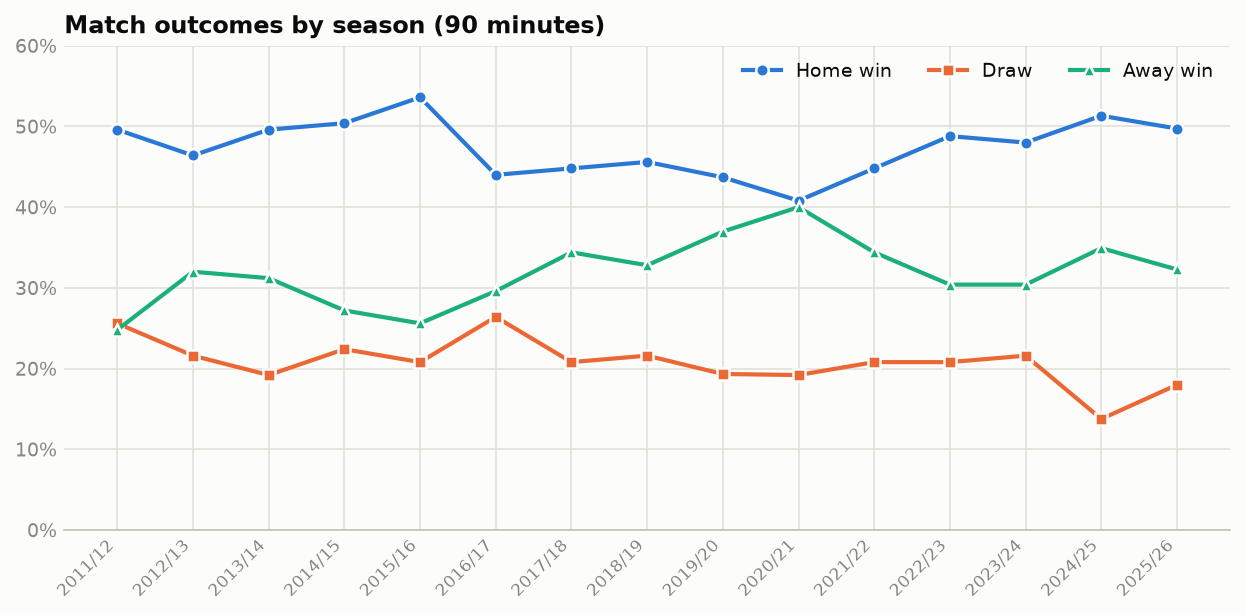

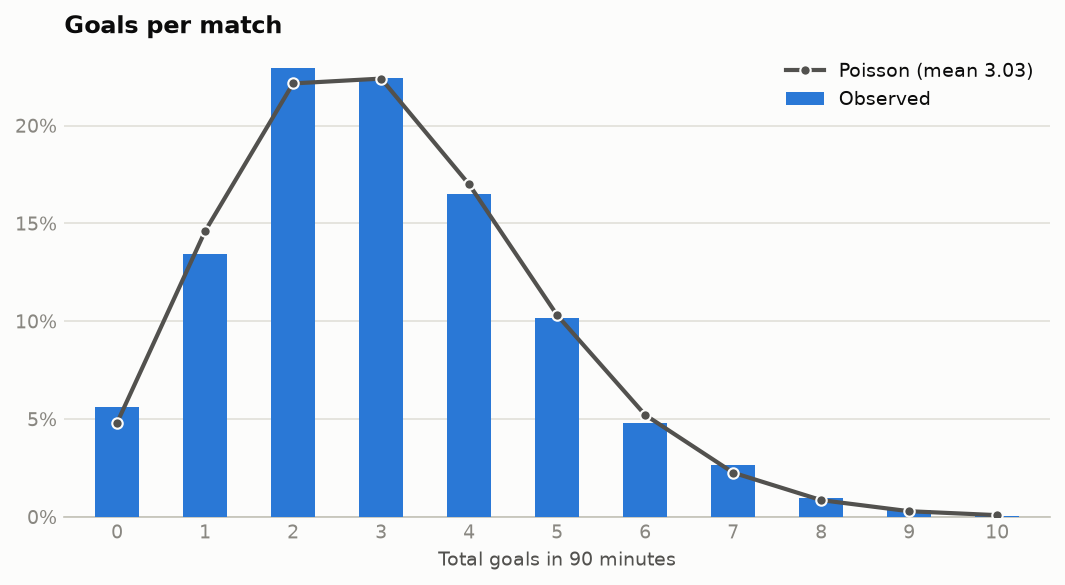

In [8]:
from src.plots import plot_outcome_shares, plot_goal_histogram
import matplotlib.pyplot as plt
fig1 = plot_outcome_shares(full, cfg.paths.outputs / "eda_outcome_shares.png"); plt.show()
fig2 = plot_goal_histogram(full, cfg.paths.outputs / "eda_goals.png"); plt.show()

## 5. Build leakage-safe features

Decide the forecast mode and the **prediction cutoff** first, then restrict the table to what was known at that moment
(`as_of`): later results are hidden, and in a replay the participants of knockout ties not yet determined are hidden too.

Features are computed in one chronological pass: a match's features come from team state frozen **before** the match
(Elo, rolling goals scored/conceded over the previous 5 and 10 matches, recent points, opponent strength, rest days, venue),
and the state is updated **after** the features are recorded.

In [9]:
mode, cutoff, season, mode_notes = pl.resolve_mode(cfg, full)
label, banner = pl.describe_mode(mode, season, cutoff)
for n in mode_notes:
    print("NOTE:", n)
print("=" * len(banner)); print(banner); print("=" * len(banner))

visible = as_of(full, cutoff, mask_undetermined_knockout=(mode != MODE_LIVE))
features, builder = build_features(visible)       # ordinary one-step-ahead features
frozen = build_frozen_features(visible)           # same matches, features frozen at each season's start (simulator horizon)
print(f"\ncutoff {cutoff}: {int(visible['is_completed'].sum()):,} completed matches visible; "
      f"{len(features):,} feature rows x {features.shape[1]} columns")
display(features[features["is_completed"]].tail(5)[["utc_date", "home_team_id", "away_team_id", "result", "elo_home", "elo_away",
                                                    "elo_diff", "gf5_home", "ga5_home", "pts5_home", "rest_days_home"]])

23:11:57 WARNING ucl.pipeline: 2026/27: only 0 of 144 league-phase fixtures found in the data (football-data.org token present: False). Official participants/fixtures unavailable. Falling back to HISTORICAL_REPLAY (clearly labelled; not a forecast of the current season).


NOTE: 2026/27: only 0 of 144 league-phase fixtures found in the data (football-data.org token present: False). Official participants/fixtures unavailable. Falling back to HISTORICAL_REPLAY (clearly labelled; not a forecast of the current season).
HISTORICAL REPLAY of 2025/26 as of 2025-09-01 - NOT a forecast of the current season


23:11:57 INFO    ucl.features: skipping 45 rows with an undetermined team


23:11:58 INFO    ucl.features: skipping 45 rows with an undetermined team



cutoff 2025-09-01 00:00:00: 1,808 completed matches visible; 1,952 feature rows x 37 columns


,utc_date,home_team_id,away_team_id,result,elo_home,elo_away,elo_diff,gf5_home,ga5_home,pts5_home,rest_days_home
1803,2025-04-29 19:00:00,arsenal,paris-saint-germain,A,1664.737174,1648.523201,16.213974,3.2,1.0,2.6,13.0
1804,2025-04-30 19:00:00,barcelona,inter,D,1658.656479,1656.783176,1.873303,2.2,1.2,2.0,15.0
1805,2025-05-06 19:00:00,inter,barcelona,H,1658.684522,1656.755132,1.929389,2.2,1.4,2.2,6.0
1806,2025-05-07 19:00:00,paris-saint-germain,arsenal,H,1660.819063,1652.441312,8.377750,1.4,1.0,1.8,8.0
1807,2025-05-31 19:00:00,paris-saint-germain,inter,H,1668.737932,1666.781620,1.956313,1.8,1.0,2.4,24.0


In [10]:
# Leakage test, executed on the real data: rewrite EVERY result in the second half of history; the first half's features
# must not change by a single bit (features only ever depend on earlier matches).
tampered = visible.copy()
cut_row = int(len(tampered) * 0.5)
order = tampered.sort_values(["utc_date", "match_id"]).index
late = order[cut_row:]
tampered.loc[late, ["home_goals_90", "away_goals_90", "home_goals_aet", "away_goals_aet"]] = 9
f_tampered, _ = build_features(tampered)
first_half = features.sort_values(["utc_date", "match_id"]).iloc[: int(len(features) * 0.40)]
same = f_tampered.set_index("match_id").loc[first_half["match_id"]]
from src.features import FEATURE_COLUMNS
pd.testing.assert_frame_equal(first_half.set_index("match_id")[FEATURE_COLUMNS], same[FEATURE_COLUMNS])
print("OK - features of earlier matches are unchanged when all later results are rewritten: no look-ahead.")

23:11:59 INFO    ucl.features: skipping 45 rows with an undetermined team


OK - features of earlier matches are unchanged when all later results are rewritten: no look-ahead.


## 6. Train baseline and ML models

Five learners are compared against a **no-skill climatology baseline** (the training-period H/D/A frequencies):

| model | what it is |
|---|---|
| `elo` | Elo win expectancy plus a one-parameter draw model (**baseline A**) |
| `logistic_elo`, `logistic` | multinomial logistic regression on Elo only / Elo + form (**B**) |
| `poisson_elo`, `poisson` | two Poisson regressions for home/away goals -> scoreline -> H/D/A (**D**) |
| `catboost` | gradient-boosted trees on all features (**C**, optional) |

Imputation and scaling are fitted inside each model on the **training rows only**. No hyper-parameter search is run: with a
couple of thousand matches, tuning would mostly fit noise.

In [11]:
ev = pl.run_evaluation(features, frozen, cfg, cutoff)      # fits every model on every split / fold (~1 min with CatBoost)
split = ev["split"]
print("Chronological split (older -> newer, no overlap):")
display(split.describe())
print("Models:", list(ev["factories"]))

Chronological split (older -> newer, no overlap):


,split,seasons,start,end,n_matches
0,train,"2011/12, 2012/13, 2013/14, 2014/15, 2015/16, 2...",2011-09-13 18:45:00,2021-05-29 19:00:00,1244
1,validation,"2021/22, 2022/23",2021-09-14 16:45:00,2023-06-10 19:00:00,250
2,test,"2023/24, 2024/25",2023-09-19 16:45:00,2025-05-31 19:00:00,314


Models: ['climatology', 'elo', 'logistic_elo', 'poisson_elo', 'logistic', 'poisson', 'catboost']


## 7. Chronological validation

Two horizons are scored, because they answer different questions:

* **`one_step_ahead`** - features computed just before each match: how good is the model at forecasting the *next* match?
* **`frozen_state`** - features frozen at the *start* of the season, applied to every match of it. This is exactly how the
  tournament simulator predicts (ratings are fixed at the cutoff and used for matches weeks or months later), so the model
  for the simulation is **selected on this horizon**, using only rolling-origin folds that end *before* the test seasons.

Metrics: multiclass log loss (primary), multiclass Brier score, accuracy, and class-wise expected calibration error.

In [12]:
fixed = ev["fixed"].metrics
tbl = (fixed[fixed["split"].isin(["validation", "test"])]
       .pivot_table(index="model", columns=["horizon", "split"], values="log_loss"))
print("Log loss on the fixed validation / test seasons (lower is better):"); display(tbl.round(4))
print("Test-season sizes:", {s: int(len(p)) for s, p in (("validation", split.val), ("test", split.test))})

Log loss on the fixed validation / test seasons (lower is better):


horizon      frozen_state            one_step_ahead           
split                test validation           test validation
model                                                         
catboost           0.9520     0.9764         0.9451     0.9328
climatology        1.0202     1.0475         1.0202     1.0475
elo                0.9565     0.9551         0.9382     0.9403
logistic           0.9702     0.9545         0.9737     0.9237
logistic_elo       0.9833     0.9628         0.9564     0.9455
poisson            0.9659     0.9542         0.9315     0.9181
poisson_elo        0.9614     0.9568         0.9434     0.9417

Test-season sizes: {'validation': 250, 'test': 314}


Rolling-origin (expanding window), folds for seasons <= 2022/23 (869 out-of-sample matches per model):


,model (frozen_state),log_loss,brier,accuracy,ece
0,elo,0.9607,0.5684,0.5650,0.0792
1,logistic_elo,0.9616,0.5659,0.5639,0.0688
2,poisson_elo,0.9619,0.5695,0.5627,0.0810
3,poisson,0.9631,0.5709,0.5489,0.0713
4,logistic,0.9650,0.5683,0.5627,0.0727
5,catboost,0.9790,0.5785,0.5547,0.0850
6,climatology,1.0607,0.6425,0.4465,0.0715


,model (one_step_ahead),log_loss,brier,accuracy,ece
0,poisson,0.9381,0.5545,0.5639,0.0707
1,logistic,0.9409,0.5531,0.5731,0.0698
2,catboost,0.9470,0.5598,0.5696,0.0686
3,elo,0.9483,0.5600,0.5662,0.0722
4,poisson_elo,0.9492,0.5609,0.5650,0.0774
5,logistic_elo,0.9494,0.5579,0.5800,0.0687
6,climatology,1.0607,0.6425,0.4465,0.0715


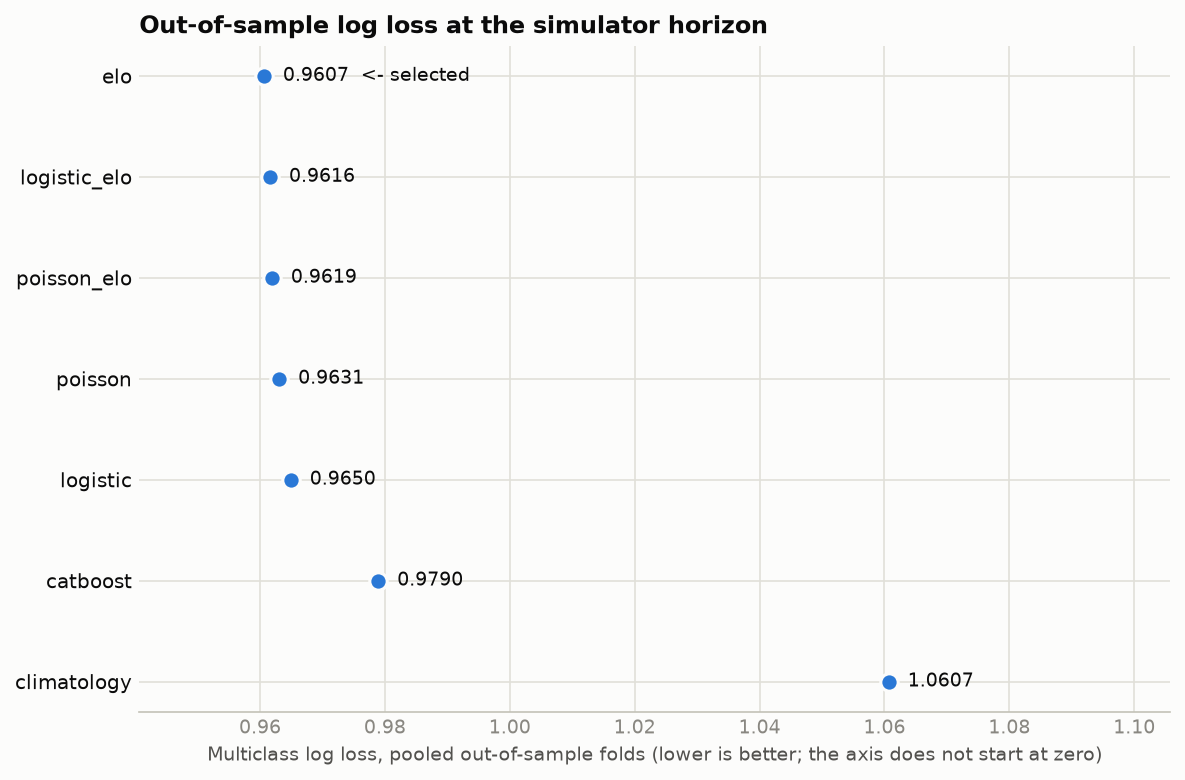

In [13]:
from src.evaluation import summarise_rolling, HORIZON_FROZEN, HORIZON_ONE_STEP
last_val = ev["last_val_season"]
sel = ev["selection"]
pooled = {h: summarise_rolling(ev["rolling"][h].folds, last_val) for h in (HORIZON_ONE_STEP, HORIZON_FROZEN)}
print(f"Rolling-origin (expanding window), folds for seasons <= {season_label(last_val)} "
      f"({int(pooled[HORIZON_FROZEN]['n_test_matches'].iloc[0])} out-of-sample matches per model):")
display(pooled[HORIZON_FROZEN][["model", "log_loss", "brier", "accuracy", "ece"]].round(4).rename(columns={"model": "model (frozen_state)"}))
display(pooled[HORIZON_ONE_STEP][["model", "log_loss", "brier", "accuracy", "ece"]].round(4).rename(columns={"model": "model (one_step_ahead)"}))
from src.plots import plot_model_comparison
plot_model_comparison(pooled[HORIZON_FROZEN], sel.chosen, "Out-of-sample log loss at the simulator horizon"); plt.show()

In [14]:
print("MODEL SELECTION  (rule:", sel.rule + ")"); display(sel.table.round(4))
for n in sel.notes:
    print(" -", n)
print("\nCaveats:")
for c in ev["caveats"]:
    print(" -", c)

MODEL SELECTION  (rule: one_se)


,model,selection_log_loss,diff_vs_best,se_of_diff,within_1se_of_best,complexity
0,elo,0.9607,0.0000,0.0000,True,1
1,logistic_elo,0.9616,0.0010,0.0083,True,2
2,poisson_elo,0.9619,0.0013,0.0019,True,3
3,poisson,0.9631,0.0024,0.0040,True,6
4,logistic,0.9650,0.0043,0.0087,True,5
5,catboost,0.9790,0.0183,0.0096,False,7


 - Selection basis: horizon-matched (frozen-state) rolling-origin folds for seasons <= 2022/23, 869 matches. The simulator freezes team state at the cutoff, so models are compared in exactly that setting; the test seasons were not used to choose.
 - With 869 selection matches, ['logistic_elo', 'poisson_elo', 'poisson', 'logistic'] cannot be statistically distinguished from 'elo' (difference within one standard error).

Caveats:
 - train=1244, validation=250, test=314 matches. A multiclass log-loss standard error on a few hundred matches is roughly 0.03-0.04, so model differences smaller than that are within noise.
 - The test period has fewer than 500 matches: treat its metrics as a rough health check, not a precise ranking of models.
 - Calibration bins hold only a few dozen matches each; reliability curves are indicative only.


Calibration of 'elo' on 1183 pooled out-of-sample predictions (equal-count bins); class-wise ECE = 0.038


mean_predicted               observed_frequency              
class              A      D      H                  A      D      H
bin                                                                
1              0.130  0.157  0.245              0.076  0.152  0.202
2              0.210  0.202  0.367              0.239  0.168  0.294
3              0.266  0.221  0.442              0.249  0.208  0.396
4              0.320  0.231  0.506              0.335  0.259  0.508
5              0.392  0.238  0.583              0.513  0.228  0.609
6              0.538  0.243  0.712              0.619  0.193  0.756

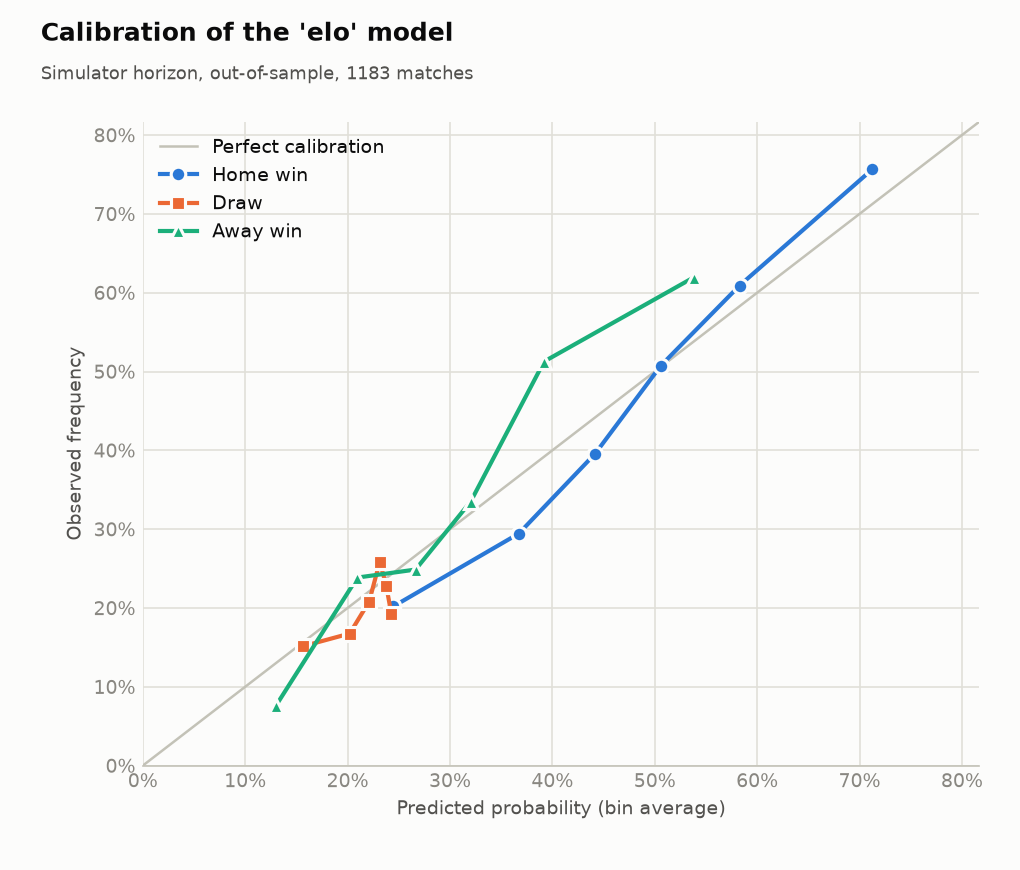

Reading it: points near the diagonal mean the stated probability matches how often the outcome happened. Bins hold ~200 matches, so deviations of a few points are within noise; no claim of exact calibration is made.


In [15]:
from src.evaluation import calibration_table, expected_calibration_error
from src.plots import plot_calibration
y_pool, p_pool = ev["rolling"][HORIZON_FROZEN].pooled_predictions(sel.chosen)
cal = calibration_table(y_pool, p_pool, n_bins=6)
print(f"Calibration of '{sel.chosen}' on {len(y_pool)} pooled out-of-sample predictions (equal-count bins); "
      f"class-wise ECE = {expected_calibration_error(y_pool, p_pool, 6):.3f}")
display(cal.round(3).pivot_table(index="bin", columns="class", values=["mean_predicted", "observed_frequency"]).round(3))
cal_png = plot_calibration(cal, cfg.paths.outputs / "calibration.png", title=f"Calibration of the '{sel.chosen}' model",
                           subtitle=f"Simulator horizon, out-of-sample, {len(y_pool)} matches")
display(Image(filename=str(cal_png)))
print("Reading it: points near the diagonal mean the stated probability matches how often the outcome happened. "
      "Bins hold ~200 matches, so deviations of a few points are within noise; no claim of exact calibration is made.")

## 8. Select and fit the model using only information available by the cutoff

The selected model is re-fitted on every completed match before the cutoff - nothing later. The team state (Elo ratings,
form) used by the simulator is the snapshot after the last of those matches.

In [16]:
chosen = sel.chosen
model = pl.fit_final_model(features, ev["factories"], chosen)
train_rows = features[features["is_completed"]]
assert train_rows["utc_date"].max() < cutoff, "training data must end before the cutoff"
print(f"selected model: {chosen!r}")
print(f"fitted on {len(train_rows):,} matches from {train_rows['utc_date'].min():%Y-%m-%d} to {train_rows['utc_date'].max():%Y-%m-%d} "
      f"(cutoff {cutoff:%Y-%m-%d %H:%M})")
ratings = pd.Series(builder.elo.ratings).sort_values(ascending=False)
names = pl.build_team_directory(visible).set_index("team_id")["team_name"]
display(pd.DataFrame({"club": ratings.head(10).index.map(names), "elo": ratings.head(10).values.round(0).astype(int)}))

selected model: 'elo'
fitted on 1,808 matches from 2011-09-13 to 2025-05-31 (cutoff 2025-09-01 00:00)


,club,elo
0,Real Madrid CF,1692
1,FC Bayern München,1690
2,Paris Saint-Germain FC,1689
3,Liverpool FC,1682
4,Manchester City FC,1666
5,FC Barcelona,1649
6,FC Internazionale Milano,1647
7,Arsenal FC,1645
8,Borussia Dortmund,1624
9,Chelsea FC,1613


## 9. Simulate the remaining tournament

For each of the simulated tournaments: every **completed** league-phase result is kept as it is, only unplayed matches are
simulated; standings follow the official tie-breakers; positions 1-8 go to the round of 16, 9-24 to the play-offs, 25-36 are
out; the knockout draw is sampled from the outcomes consistent with the pairings already known; two-legged ties are
aggregated (no away-goals rule) with extra time and penalties; the final is a single neutral match.

In [17]:
if mode == MODE_SCENARIO:
    setup = build_scenario_setup(cfg.scenario_pots, model, builder, season=season, seed=cfg.seed, label=label)
else:
    setup = build_setup_from_matches(visible, season, model, builder, mode=mode, label=label, cutoff=cutoff)

print(f"{setup.label}\n  league matches already played: {int(setup.league_played.sum())} / 144 | "
      f"known knockout legs: {setup.known_ko.n_known_legs}")
sim = simulate_tournament(setup, SimConfig(n_sims=cfg.n_sims, seed=cfg.seed))
print(f"{sim.n_sims:,} simulated tournaments | seed {sim.seed} | knockout draw outcomes consistent with the data: {sim.n_draw_outcomes}")
for team, note in sim.notes["team_notes"].items():
    print(f"  note for {team}: {note}")

HISTORICAL REPLAY of 2025/26 as of 2025-09-01 (uses only data before that date)
  league matches already played: 0 / 144 | known knockout legs: 0


10,000 simulated tournaments | seed 42 | knockout draw outcomes consistent with the data: 4096
  note for bodo-glimt: no earlier Champions League match in the data: default Elo rating, form unknown
  note for kairat: no earlier Champions League match in the data: default Elo rating, form unknown
  note for paphos: no earlier Champions League match in the data: default Elo rating, form unknown
  note for union-saint-gilloise: no earlier Champions League match in the data: default Elo rating, form unknown


In [18]:
sens = pl.model_sensitivity(setup, builder, features, ev["factories"], [m for m in ev["factories"] if m != "climatology"],
                            chosen, cfg, sim) if cfg.run_sensitivity else None
replay_check = pl.replay_check(full, season, sim) if mode == MODE_REPLAY else None

## 10. Championship probabilities

In [19]:
print("=" * len(banner)); print(banner); print("=" * len(banner))
champ = sim.champion_table()
shown = champ.head(20).assign(
    probability=lambda d: (100 * d["champion_probability"]).map("{:.1f}%".format),
    interval_95=lambda d: [f"{100*a:.1f}% - {100*b:.1f}%" for a, b in zip(d["ci95_low"], d["ci95_high"])])
display(shown[["rank", "team_name", "simulated_championships", "probability", "interval_95"]].set_index("rank"))
print(f"sum of probabilities over all {len(champ)} clubs = {champ['champion_probability'].sum():.6f}")
print("\nHow to read the interval:", pl.CI_INTERPRETATION)

HISTORICAL REPLAY of 2025/26 as of 2025-09-01 - NOT a forecast of the current season


,team_name,simulated_championships,probability,interval_95
rank,,,,
1,Real Madrid CF,1422,14.2%,13.5% - 14.9%
2,FC Bayern München,1330,13.3%,12.6% - 14.0%
3,Paris Saint-Germain FC,1266,12.7%,12.0% - 13.3%
4,Liverpool FC,1193,11.9%,11.3% - 12.6%
5,Manchester City FC,961,9.6%,9.0% - 10.2%
6,FC Barcelona,732,7.3%,6.8% - 7.8%
7,Arsenal FC,672,6.7%,6.2% - 7.2%
8,FC Internazionale Milano,602,6.0%,5.6% - 6.5%
9,Borussia Dortmund,430,4.3%,3.9% - 4.7%


sum of probabilities over all 36 clubs = 1.000000

How to read the interval: ci95_low/ci95_high is a 95% Wilson score interval for the share of simulated tournaments won. It measures only the random error from using a finite number of simulations (it shrinks as n_sims grows). It does NOT include uncertainty about the match model, the ratings, or the unplayed draw, so the true forecast uncertainty is larger.


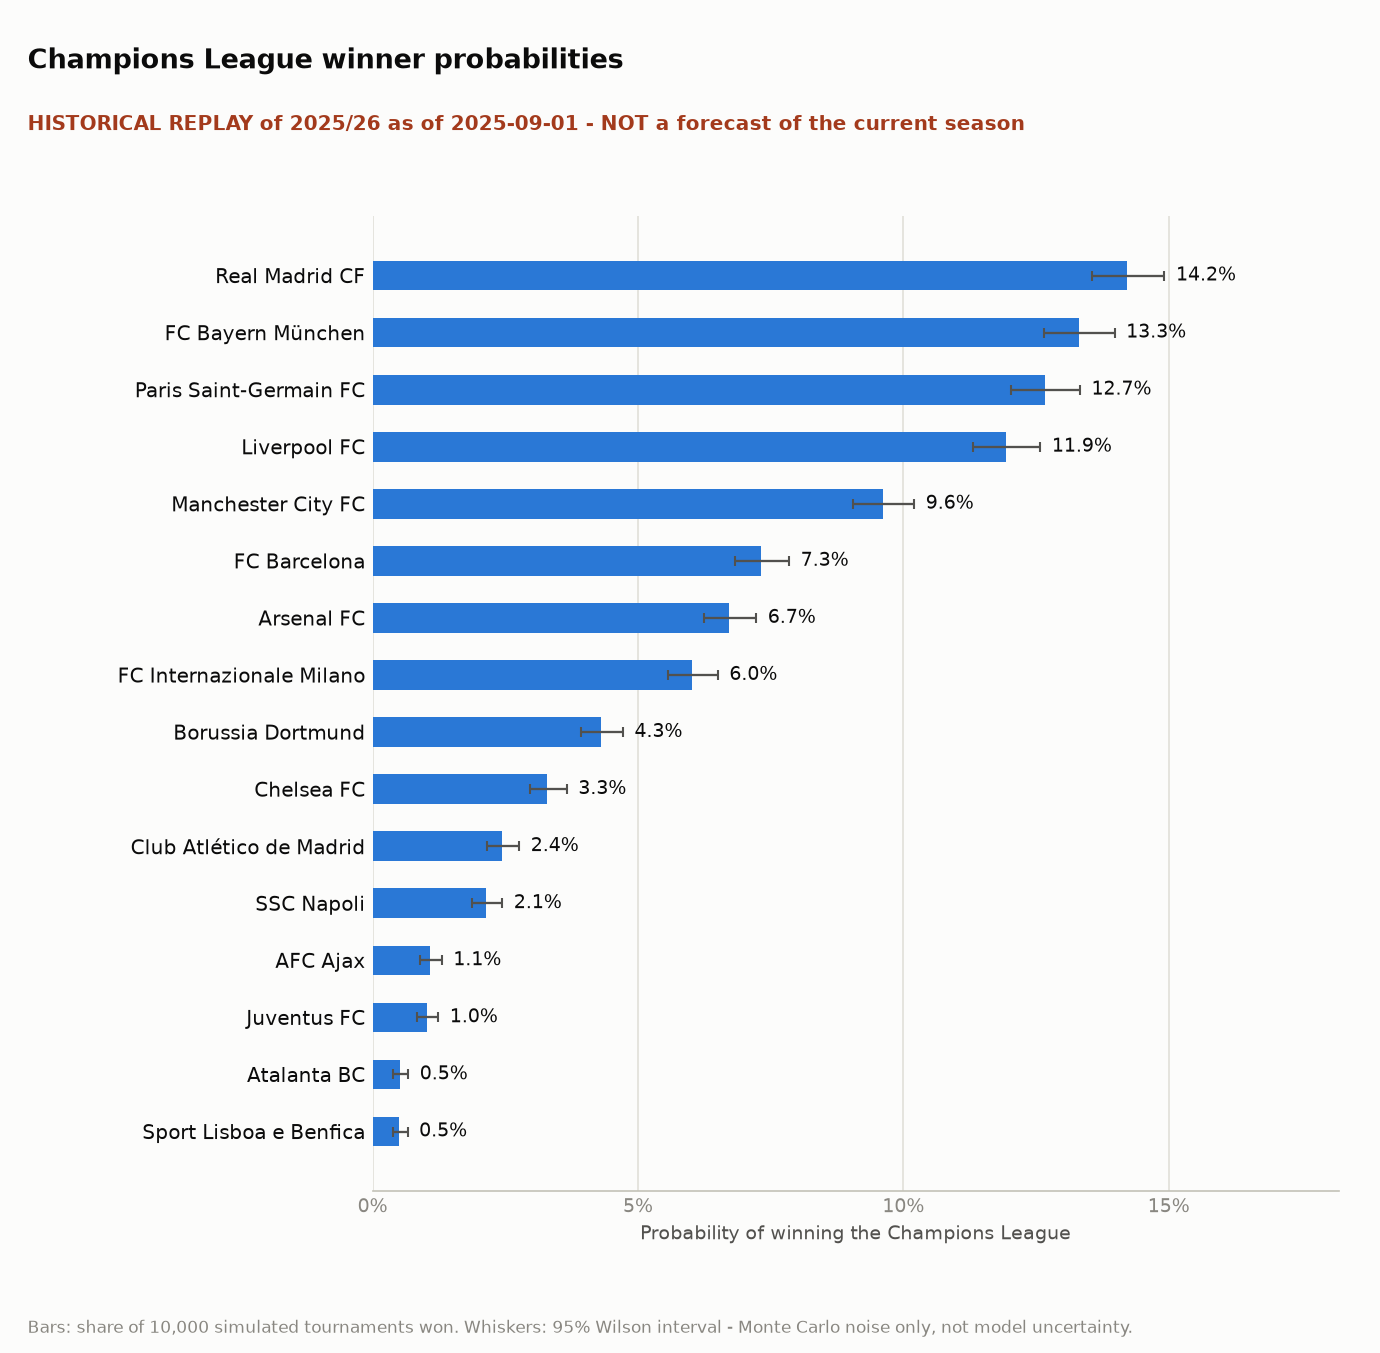

In [20]:
plots_path = pl.plot_champion_probabilities(champ, cfg.paths.outputs / "champion_probabilities.png",
                                            title="Champions League winner probabilities", banner=banner, n_sims=sim.n_sims)
display(Image(filename=str(plots_path)))

In [21]:
q = sim.qualification_table().head(16)
cols = ["team_name", "p_top8_direct_r16", "p_playoff", "p_eliminated", "p_reach_quarter_final", "p_reach_final", "p_champion"]
display(q[cols].assign(**{c: (100 * q[c]).round(1) for c in cols[1:]}).rename(columns=lambda c: c.replace("p_", "% ")))
if sens is not None:
    print("Sensitivity to the model choice - championship probability under every candidate model (top 10 by the selected model):")
    display((sens.head(10).set_index("team_name").drop(columns=["team_id", "selected_model"]) * 100).round(1))
    print("A wide spread across models for a club means its probability depends on modelling choices that out-of-sample "
          "validation cannot separate; Monte Carlo intervals above do not capture this.")
if replay_check:
    print("\nPost-hoc replay check (an anecdote, not validation):", replay_check)

,team_name,% top8_direct_r16,% playoff,% eliminated,% reach_quarter_final,% reach_final,% champion
0,Real Madrid CF,62.6,33.8,3.7,62.6,25.2,14.2
1,FC Bayern München,57.3,38.1,4.6,61.0,24.2,13.3
2,Paris Saint-Germain FC,58.3,37.1,4.6,60.9,22.7,12.7
3,Liverpool FC,60.9,34.4,4.6,59.7,21.8,11.9
4,Manchester City FC,53.4,40.8,5.8,55.7,18.1,9.6
5,FC Barcelona,55.2,39.1,5.7,51.6,14.7,7.3
6,Arsenal FC,47.6,44.1,8.3,48.8,13.2,6.7
7,FC Internazionale Milano,37.4,50.9,11.7,44.0,12.3,6.0
8,Borussia Dortmund,38.2,49.9,11.8,39.9,9.6,4.3
9,Chelsea FC,30.5,52.5,17.0,34.4,7.4,3.3


Sensitivity to the model choice - championship probability under every candidate model (top 10 by the selected model):


,p_elo,p_logistic_elo,p_poisson_elo,p_logistic,p_poisson,p_catboost,range_across_models
team_name,,,,,,,
Real Madrid CF,14.2,17.0,13.6,10.2,6.2,16.2,10.8
FC Bayern München,13.3,16.0,11.6,10.0,10.5,6.8,9.2
Paris Saint-Germain FC,12.7,14.9,11.8,25.3,24.3,16.6,13.5
Liverpool FC,11.9,14.2,11.4,10.7,9.6,8.0,6.2
Manchester City FC,9.6,9.8,9.4,5.5,3.4,7.5,6.4
FC Barcelona,7.3,7.4,7.4,8.1,9.3,9.6,2.3
Arsenal FC,6.7,5.7,6.3,18.3,10.3,17.5,12.6
FC Internazionale Milano,6.0,5.8,6.3,3.0,3.5,9.8,6.8
Borussia Dortmund,4.3,3.0,4.2,2.0,2.9,2.8,2.3


A wide spread across models for a club means its probability depends on modelling choices that out-of-sample validation cannot separate; Monte Carlo intervals above do not capture this.

Post-hoc replay check (an anecdote, not validation): {'actual_champion': 'Paris Saint-Germain FC', 'assigned_probability': 0.1266, 'rank_in_forecast': 3, 'caveat': 'A single season cannot validate calibration; this is an anecdote, not evidence of accuracy.'}


## 11. Save predictions and model artifacts

In [22]:
result = pl.PipelineResult(cfg, visible, provenance, features, ev, chosen, setup, sim, mode, label, banner, cutoff, mode_notes,
                           replay_check, sens, model, builder)
written = pl.save_outputs(result, started_at=None)
for name, path in written.items():
    print(f"{name:34s} {path.relative_to(ROOT)}   ({path.stat().st_size / 1024:,.0f} KB)")

matches                            data\processed\matches.csv   (564 KB)
model_metrics                      outputs\model_metrics.csv   (26 KB)
champion_probabilities             outputs\champion_probabilities.csv   (4 KB)
qualification_probabilities        outputs\qualification_probabilities.csv   (4 KB)
final_standings_probabilities      outputs\final_standings_probabilities.csv   (11 KB)
champion_chart                     outputs\champion_probabilities.png   (110 KB)
calibration_table                  outputs\calibration_table.csv   (6 KB)
calibration_chart                  outputs\calibration.png   (91 KB)
elo_ratings                        outputs\elo_ratings_at_cutoff.csv   (7 KB)
model_artifact                     outputs\model.joblib   (3 KB)
champion_probabilities_by_model    outputs\champion_probabilities_by_model.csv   (3 KB)
run_metadata                       outputs\run_metadata.json   (9 KB)


In [23]:
import json
meta = json.loads((cfg.paths.outputs / "run_metadata.json").read_text(encoding="utf-8"))
print("forecast mode :", meta["forecast"]["mode"], "| live forecast:", meta["forecast"]["is_live_forecast"])
print("selected model:", meta["evaluation"]["selected_model"])
print("data          :", meta["data"]["n_completed"], "completed matches,", meta["data"]["n_teams"], "clubs")
print("assumptions   :")
for a in meta["forecast"]["assumptions"]:
    print("  -", a)

forecast mode : HISTORICAL_REPLAY | live forecast: False
selected model: elo
data          : 1808 completed matches, 108 clubs
assumptions   :
  - Ratings and form are frozen at the prediction cutoff and are not updated during a simulated tournament.
  - Scores are independent Poisson draws; extra time uses one third of the 90-minute rates; shoot-outs are a coin flip.
  - League-phase ties still level after the opponent-based criteria are broken at random (disciplinary record and club coefficient are not available).
  - The knockout draw is sampled uniformly from all outcomes consistent with the pairings already known; no other draw restrictions are modelled.
  - Monte Carlo intervals measure simulation noise only, not uncertainty in the match model.


## Limitations you should keep in mind

* **Sample size.** About 2,000 matches in 15 seasons; log-loss differences between the candidate models are within one or two
  standard errors, so the models cannot be reliably ranked - which is why the simplest adequate model is chosen.
* **Only Champions League matches are observed.** No domestic-league form, squad values, injuries, xG or coefficients, so
  clubs with little Champions League history are rated at the default and flagged in the output.
* **Ratings are frozen at the cutoff** during the simulation and scores are independent Poisson draws; real tournaments
  have momentum, injuries and tactics that this ignores.
* **Intervals are Monte Carlo noise only.** They shrink with more simulations; the uncertainty about the model itself is
  larger and is shown separately by the sensitivity table.
* **Tie-break fallbacks.** Disciplinary record and club coefficient are unavailable, so remaining ties are broken at random.
* A single replayed season (e.g. "PSG won and the model gave them X%") proves nothing about calibration.